# Step 1: archive inspection and time-series construction

We checked the 35 monthly folders and built hourly and daily counts for **wp** from the prepared CSVs.
The preparation script processed the whole archive without filtering dates.

Requests were assigned to the dates they happened, rather than their backup dates.
Missing counts were left unknown, and large counts were kept unchanged.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_folder = Path.cwd()
if project_folder.name == 'notebooks':
    project_folder = project_folder.parent

outputs_folder = project_folder / 'outputs'
data_folder = project_folder / 'data'


In [2]:
df_hourly = pd.read_csv(outputs_folder / 'tables/hourly.csv')
df_daily = pd.read_csv(outputs_folder / 'tables/daily.csv')
df_audit = pd.read_csv(outputs_folder / 'audit/audit.csv')
df_monthly = pd.read_csv(outputs_folder / 'audit/months.csv', dtype={'month': str})
quality_summary = pd.read_csv(outputs_folder / 'audit/quality_summary.csv')


## Question 1: which files and dates do we have?

`months.csv` is in **`outputs/audit/months.csv`**.
All **35 expected folders, April 2023 to February 2026, are present**.

- `folder_present=False`: the folder is missing, so we do not know its contents.
- `folder_present=True` and `file_count=0`: the folder exists but is empty.

A folder can exist even when some daily log files are missing.

In [3]:
assert len(df_monthly) == 35
assert df_monthly['folder_present'].all()

inventory_columns = [
    'month', 'folder_present', 'file_count',
    'selected_access_files', 'unique_selected_files',
]
df_monthly[inventory_columns]


,month,folder_present,file_count,selected_access_files,unique_selected_files
0,202304,True,60,38,25
1,202305,True,96,47,31
2,202306,True,109,45,30
3,202307,True,113,46,31
4,202308,True,117,47,31
5,202309,True,109,45,30
6,202310,True,115,46,31
7,202311,True,123,45,30
8,202312,True,141,47,31
9,202401,True,139,46,31


### Log files included in the analysis

| Filename | What it records | Included in wp counts? |
| --- | --- | --- |
| `access.wp.log` or `access.wp.log.1` | Requests to the public WordPress website | Yes |
| `access.doktor.log.1` | Requests to the academic paper search website | No; separate series |
| `error.<service>.log.1` | Server error messages | No |
| `access.nisl-1-stream.log.1` | TCP connections, rather than website requests | No |

A request with status 400, 404 or 500 still belongs in the request count.
It is a request that failed, not an entry from a server error-log file.
The preparation script reads only wp and doktor HTTP access logs.
[Dataset format documentation](https://github.com/cdsl-research/website-access-logs-public#log-format).

In [4]:
print('HTTP example:', next(data_folder.rglob('access.wp.log.1')).name)
print('Error-log example:', next(data_folder.rglob('error.*.log.1')).name)
print('TCP example:', next(data_folder.rglob('access.nisl-1-stream.log.1')).name)


HTTP example: access.wp.log.1
Error-log example: error.clematis.tak-cslab.org.log.1
TCP example: access.nisl-1-stream.log.1


### Backup dates compared with request dates

We examined three wp files, including a backup taken on the first day of a month.
The table shows each backup-folder name, the timestamp on the file's first line,
and the earliest and latest request times listed in the audit.

The first line is not always the earliest request, because log lines may be out of order.

In [5]:
wp_files = df_audit[df_audit['service'] == 'wp'].copy()
month_boundary = wp_files['backup_label'] == 'log-backup-20230501000001'
sample_files = pd.concat([
    wp_files.head(1),
    wp_files[month_boundary],
    wp_files.tail(1),
])


In [6]:
sample_dates = []
for file in sample_files.itertuples():
    with (data_folder / file.file).open(encoding='utf-8') as source:
        first_line = source.readline()
    timestamp = first_line.split('[', 1)[1].split(']', 1)[0]
    sample_dates.append([file.backup_label, timestamp, file.first_event_local, file.last_event_local])

sample_columns = ['Backup folder', 'First record timestamp', 'First event (JST)', 'Last event (JST)']
pd.DataFrame(sample_dates, columns=sample_columns)


,Backup folder,First record timestamp,First event (JST),Last event (JST)
0,log-backup-20230403072346,02/Apr/2023:00:00:44 +0900,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
1,log-backup-20230501000001,30/Apr/2023:00:01:57 +0900,2023-04-30T00:01:57+09:00,2023-04-30T23:59:47+09:00
2,log-backup-20260204000002,03/Feb/2026:00:00:14 +0900,2026-02-03T00:00:14+09:00,2026-02-03T23:59:41+09:00


The backup taken on **1 May 2023** contained requests from **30 April**.
Those requests were counted in April, even though the file was in the May folder.
The last example was similar: the 4 February 2026 backup contained 3 February requests.

The earliest wp request was **2 April 2023 at 00:00:44 JST**.
The latest was **3 February 2026 at 23:59:41 JST**.

The script read the timezone offset in each request timestamp and grouped requests using
**Japan Standard Time (JST, UTC+09:00)**. `months.csv` was used to describe the backup folders,
not to calculate monthly traffic. No monthly traffic series was calculated in this notebook.

## Question 2: what did we find when checking all the files?

`outputs/audit/audit.csv` has one row per file.
For wp and doktor together, the script checked **1,576 files**.
It read the requests in **1,244 different files** and skipped **332 identical copies**.
It identifies copies by comparing file hashes, so it does not need to parse them again.

The tables below show which files were skipped, how many requests were counted,
any lines the script could not read, and the first and last request dates.
The summary also shows hours with no recorded requests.

In [7]:
audit_columns = [
    'file', 'duplicate_of', 'records_used', 'parse_errors',
    'first_event_local', 'last_event_local',
]
df_audit[audit_columns]


,file,duplicate_of,records_used,parse_errors,first_event_local,last_event_local
0,202304/log-backup-20230403072346/access.doktor...,NaN,66,0,2023-03-29T01:13:53+09:00,2023-03-29T16:27:38+09:00
1,202304/log-backup-20230403072346/access.wp.log.1,NaN,7071,0,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
2,202304/log-backup-20230403072528/access.doktor...,202304/log-backup-20230403072346/access.doktor...,0,0,2023-03-29T01:13:53+09:00,2023-03-29T16:27:38+09:00
3,202304/log-backup-20230403072528/access.wp.log.1,202304/log-backup-20230403072346/access.wp.log.1,0,0,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
4,202304/log-backup-20230404000001/access.wp.log.1,NaN,10837,0,2023-04-03T00:00:30+09:00,2023-04-03T23:59:53+09:00
...,...,...,...,...,...,...
1571,202602/log-backup-20260202000002/access.wp.log.1,NaN,5388,0,2026-02-01T00:00:06+09:00,2026-02-01T23:59:57+09:00
1572,202602/log-backup-20260203000001/access.doktor...,NaN,4381,0,2026-02-02T00:00:25+09:00,2026-02-02T23:59:31+09:00
1573,202602/log-backup-20260203000001/access.wp.log.1,NaN,5741,0,2026-02-02T00:00:22+09:00,2026-02-02T23:59:39+09:00
1574,202602/log-backup-20260204000002/access.doktor...,NaN,3184,0,2026-02-03T00:04:06+09:00,2026-02-03T23:59:07+09:00


In [8]:
summary_columns = [
    'service', 'unique_files', 'duplicate_files', 'records_used',
    'parse_errors', 'unknown_hours', 'complete_days',
]
quality_summary[summary_columns]


,service,unique_files,duplicate_files,records_used,parse_errors,unknown_hours,complete_days
0,doktor,292,331,507309,0,18017,291
1,wp,952,1,4779893,0,2183,952


### Repeated old files and missing days

- **wp:** 952 different files and one skipped copy; **4,779,893 requests counted**.
- **doktor:** 331 files are copies of the same 66-request log from **29 March 2023**.
  The next different log starts on **8 March 2025**. Copying an old file does not give us new traffic records.
- Both services have **no traffic records from 23 July to 27 August 2025**: 36 days.
- wp also has **no traffic records from 7 December 2024 to 8 January 2025**: 33 days.

There is a backup dated 23 July, but its wp file contains only 22 July requests.
It does not provide records for 23 July.

**We do not know why those days have no records.** Files may be missing, logging may have stopped,
or the website may have been unavailable. We left the counts as missing (`NaN`)
rather than assuming there were zero requests.

`missing_observations.ipynb` shows the missing days and the files just before and after them.

In [9]:
gaps = pd.read_csv(outputs_folder / 'audit/missing_intervals.csv')
wp_gaps = gaps[gaps['service'] == 'wp']
wp_gaps.sort_values('hours', ascending=False)


,service,start_local,end_local_exclusive,hours,location
18,wp,2025-07-23T00:00:00+09:00,2025-08-28T00:00:00+09:00,864,internal
15,wp,2024-12-07T00:00:00+09:00,2025-01-09T00:00:00+09:00,792,internal
7,wp,2023-03-29T00:00:00+09:00,2023-04-02T00:00:00+09:00,96,boundary
8,wp,2023-04-07T00:00:00+09:00,2023-04-11T00:00:00+09:00,96,internal
14,wp,2024-11-01T00:00:00+09:00,2024-11-04T00:00:00+09:00,72,internal
19,wp,2025-12-19T00:00:00+09:00,2025-12-22T00:00:00+09:00,72,internal
11,wp,2024-09-21T01:00:00+09:00,2024-09-23T00:00:00+09:00,47,internal
9,wp,2024-08-19T00:00:00+09:00,2024-08-20T00:00:00+09:00,24,internal
10,wp,2024-09-19T00:00:00+09:00,2024-09-20T00:00:00+09:00,24,internal
12,wp,2024-10-01T00:00:00+09:00,2024-10-02T00:00:00+09:00,24,internal


## Question 3: what do we skip, keep or reject?

**A copied file:** two files contain exactly the same bytes. The script uses a SHA-256 hash
to identify these copies within each service. It counts the file once. For later copies,
`duplicate_of` names the original and `records_used=0` means no requests were counted again.

**Repeated lines in one file:** the script keeps them. A client can send the same request
more than once in the same second, producing identical log lines. Deleting them could remove real requests.

The first wp file has **two repeated full lines beyond their first occurrences**.
The check below counts repeated lines in that one file, not across the whole archive.

In [10]:
first_wp_file = data_folder / wp_files.iloc[0]['file']
sample_lines = first_wp_file.read_text(encoding='utf-8').splitlines()
repeated_lines = pd.Series(sample_lines).duplicated().sum()

print('Extra repeated full lines in the first wp file:', repeated_lines)


Extra repeated full lines in the first wp file:

 2


### Were any records rejected?

The script rejects a line if it cannot decode its text as UTF-8, recognise the expected log format,
or read a valid timestamp. It counts blank lines separately.
Rejected lines go into `outputs/audit/parse_errors.csv`, with the source file, line number and reason.

**This run had zero rejected records.** There are no rejected examples to inspect.
When there are no failures, the script removes `parse_errors.csv`.

In [11]:
unique_files = df_audit[df_audit['duplicate_of'].isna()]
print('Rejected records:', unique_files['parse_errors'].sum())

errors_file = outputs_folder / 'audit/parse_errors.csv'
if errors_file.exists():
    display(pd.read_csv(errors_file).head())
else:
    print('No parse_errors.csv: no parsing failures were recorded.')


Rejected records: 0
No parse_errors.csv: no parsing failures were recorded.


### Unusual or failed requests can still count

The script counts a line if it can read the log fields and timestamp,
even when the request failed or looks unusual.
That includes monitoring checks, bots, scanners, and requests with 4xx or 5xx responses.
A byte-size field of `-` means the response size is unknown; the request still counts.

Examples found in the first wp file:

| Request field | Status | What the script does |
| --- | --- | --- |
| `GET / HTTP/1.0 ` (extra space at the end) | 400 | Counts it and flags the request format |
| `GET /remote/fgt_lang` (no HTTP version) | 404 | Counts it and flags the request format |
| Empty request field | 400 | Counts it and flags the request format |

`nonstandard_requests` counts requests that do not match the script's expected request pattern.
The flag alone does not mean the record should be deleted.
Also, requests outside the monitoring category can still come from bots rather than people.

In [12]:
wp_hourly_rows = df_hourly[df_hourly['service'] == 'wp']
unusual_columns = ['nonstandard_requests', 'status_4xx', 'status_5xx', 'missing_byte_values']
wp_hourly_rows[unusual_columns].sum().astype(int)


nonstandard_requests       248
status_4xx              196692
status_5xx                 109
missing_byte_values          0
dtype: int64

## Question 4: hourly and daily counts

The exported table contained one row per hour, starting on **29 March 2023**.
wp and doktor shared the same date range in the export.
wp's first recorded request was on **2 April**. We could not establish whether wp logs should exist
for the earlier days, so those hours were left unknown.

We converted the request times to JST, sorted them and created an hourly time index.

In [13]:
service = 'wp'
traffic_columns = ['requests', 'monitor_requests', 'other_requests']

hourly = df_hourly[df_hourly['service'] == service].copy()
hourly['time'] = pd.to_datetime(hourly['time_utc'], utc=True)
hourly['time'] = hourly['time'].dt.tz_convert('Asia/Tokyo')
hourly = hourly.set_index('time').sort_index()
assert hourly.index.is_unique, 'Duplicate hourly timestamps'


In [14]:
hourly_counts = hourly[traffic_columns].asfreq('h')
observation_mask = hourly['has_events'].asfreq('h').copy()
raw_hourly_counts = hourly_counts.copy()

hourly_counts.head()


,requests,monitor_requests,other_requests
time,,,
2023-03-29 00:00:00+09:00,NaN,NaN,NaN
2023-03-29 01:00:00+09:00,NaN,NaN,NaN
2023-03-29 02:00:00+09:00,NaN,NaN,NaN
2023-03-29 03:00:00+09:00,NaN,NaN,NaN
2023-03-29 04:00:00+09:00,NaN,NaN,NaN


### Hourly totals compared with retained requests

The hourly counts summed to **4,779,893 wp requests**, matching the total `records_used`
in the file audit.

The comparison used `records_used` because `parsed_records` also includes counts copied
into the audit rows for skipped files. Those copies contributed no additional requests.

In [15]:
retained_records = df_audit.loc[df_audit['service'] == service, 'records_used'].sum()
hourly_total = hourly_counts['requests'].sum()
assert hourly_total == retained_records

print('Retained records:', retained_records)
print('Hourly sum:', int(hourly_total))


Retained records: 4779893
Hourly sum: 4779893


### Missing counts and known zeros

An hour with no request records was left **missing (`NaN`)** because its traffic count was unknown.
A known zero would require evidence that logging worked throughout the hour and no requests occurred.
The access logs did not provide that evidence.

We calculated a daily total only when **all 24 JST hours had recorded requests**.
The `min_count=24` setting left the daily total missing whenever an hour was unknown.
Having records in all 24 hours still did not prove that every request within those hours was logged.

In [16]:
daily_counts = hourly_counts.resample('D').sum(min_count=24)
raw_daily_counts = daily_counts.copy()
daily_counts.head()


,requests,monitor_requests,other_requests
time,,,
2023-03-29 00:00:00+09:00,NaN,NaN,NaN
2023-03-30 00:00:00+09:00,NaN,NaN,NaN
2023-03-31 00:00:00+09:00,NaN,NaN,NaN
2023-04-01 00:00:00+09:00,NaN,NaN,NaN
2023-04-02 00:00:00+09:00,7071.0,576.0,6495.0


`requests_recorded` adds up the requests we actually found, even on a day with missing hours.
For example, if only 20 hours have records, it sums those 20 hours, while `requests` stays missing.

On a day with no records, `requests_recorded` is 0. That means **zero records found**,
not proof that the website received zero requests.

In [17]:
service_daily = df_daily[df_daily['service'] == service]
coverage_columns = [
    'date_local', 'requests', 'requests_recorded',
    'hours_with_events', 'unknown_hours',
]
service_daily[coverage_columns].head(8)


,date_local,requests,requests_recorded,hours_with_events,unknown_hours
0,2023-03-29,NaN,0,0,24
1,2023-03-30,NaN,0,0,24
2,2023-03-31,NaN,0,0,24
3,2023-04-01,NaN,0,0,24
4,2023-04-02,7071.0,7071,24,0
5,2023-04-03,10837.0,10837,24,0
6,2023-04-04,8202.0,8202,24,0
7,2023-04-05,2645.0,2645,24,0


In [18]:
coverage = pd.DataFrame({
    'Total periods': [len(hourly_counts), len(daily_counts)],
    'Missing periods': [
        hourly_counts['requests'].isna().sum(),
        daily_counts['requests'].isna().sum(),
    ],
}, index=['Hours', 'Days'])

coverage


,Total periods,Missing periods
Hours,25032,2183
Days,1043,91


## Question 5: treatment of missing values and large counts

Missing counts were left as `NaN`. Large counts were kept unchanged.
We did not fill gaps, cap spikes, remove large observations or smooth the series.
A spike could reflect real traffic, monitoring checks or scanning; no cause was assumed.

The notebook preserved:

- `raw_hourly_counts` and `raw_daily_counts`: the counts before any corrections.
- `observation_mask`: whether each hour had records. `False` means unknown, not zero requests.
- The unchanged source CSVs, including daily coverage fields and `requests_recorded`.

Training, validation and test dates have **not yet been selected**.
No cleaning thresholds or transformations have been fitted.
Their selection from training data, consistent application to later periods, and evaluation
without future information remain part of the experimental-design stage.
The original counts and observation mask remain available for comparison with any later corrections.

## Output files and fields

| Output or field | What it tells us |
| --- | --- |
| `outputs/audit/months.csv` | Which of the 35 monthly folders exist and what they contain |
| `outputs/audit/audit.csv` | Requests per file, copied files, and first and last request times |
| `outputs/tables/hourly.csv` | One row per hour, with request counts, monitoring counts, response groups and coverage flags |
| `outputs/tables/daily.csv`: `requests` | Daily total; left missing if any hour is unknown |
| `requests_recorded` | Requests actually found, including on days with missing hours |
| `outputs/audit/parse_errors.csv` | Lines the script could not read, with their file and line number; created only if needed |

## Traffic plots

The daily plot shows the whole period. The hourly plot shows the last 14 calendar days,
ending on the last day with records. Blank sections mean missing counts.
The full series are still available in `hourly_counts` and `daily_counts`.

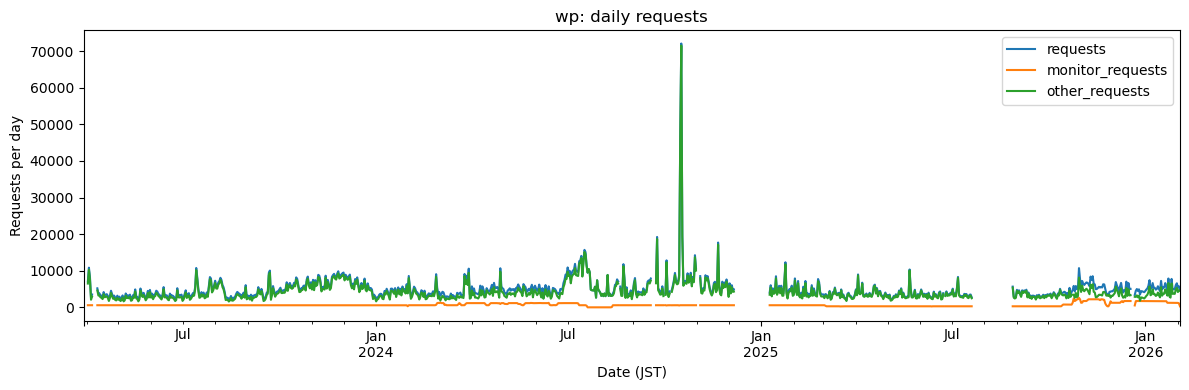

In [19]:
ax = daily_counts.plot(figsize=(12, 4))
ax.set_title(f'{service}: daily requests')
ax.set_xlabel('Date (JST)')
ax.set_ylabel('Requests per day')
plt.tight_layout()
plt.show()


In [20]:
last_hour = hourly_counts['requests'].last_valid_index()
assert last_hour is not None, 'No recorded requests to plot'

last_day = last_hour.normalize()
first_day = last_day - pd.Timedelta(days=13)
end_of_window = last_day + pd.Timedelta(days=1)

recent_hourly = hourly_counts[hourly_counts.index >= first_day]
recent_hourly = recent_hourly[recent_hourly.index < end_of_window]


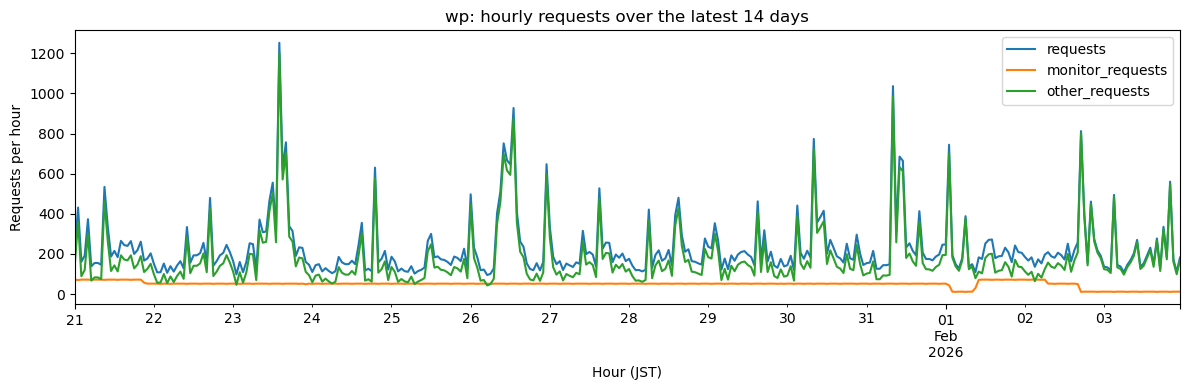

In [21]:
ax = recent_hourly.plot(figsize=(12, 4))
ax.set_title(f'{service}: hourly requests over the latest 14 days')
ax.set_xlabel('Hour (JST)')
ax.set_ylabel('Requests per hour')
plt.tight_layout()
plt.show()
